In [1]:
import pandas as pd
import numpy as np

In [3]:
calendar = pd.read_csv("../data/raw/calendar.csv")
sales = pd.read_csv("../data/raw/sales_train_validation.csv")
prices = pd.read_csv("../data/raw/sell_prices.csv")

print("Calendar:", calendar.shape)
print("Sales:", sales.shape)
print("Prices:", prices.shape)

Calendar: (1969, 14)
Sales: (30490, 1919)
Prices: (6841121, 4)


In [7]:
day_columns = [col for col in sales.columns if col.startswith("d_")]

print("Number of day columns:", len(day_columns))
print("First 5:", day_columns[:5])
print("Last 5:", day_columns[-5:])

Number of day columns: 1913
First 5: ['d_1', 'd_2', 'd_3', 'd_4', 'd_5']
Last 5: ['d_1909', 'd_1910', 'd_1911', 'd_1912', 'd_1913']


In [16]:
sales_test = sales.iloc[:100].copy()

sales_test_long = sales_test.melt(
    id_vars=[
        "id",
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id"
    ],
    value_vars=day_columns,
    var_name="d",
    value_name="sales"
)

print("Shape:", sales_test_long.shape)
print(sales_test_long.head())

Shape: (191300, 8)
                              id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_validation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_002_CA_1_validation  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_003_CA_1_validation  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_004_CA_1_validation  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_005_CA_1_validation  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1   

  state_id    d  sales  
0       CA  d_1      0  
1       CA  d_1      0  
2       CA  d_1      0  
3       CA  d_1      0  
4       CA  d_1      0  


In [17]:
sales["total_sales"] = sales[day_columns].sum(axis=1)

sales[["id", "item_id", "dept_id", "cat_id", "store_id", "state_id", "total_sales"]].sort_values(
    "total_sales",
    ascending=False
).head(20)

C:\Users\uddin\AppData\Local\Temp\ipykernel_12948\186770753.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sales["total_sales"] = sales[day_columns].sum(axis=1)


,id,item_id,dept_id,cat_id,store_id,state_id,total_sales
8412,FOODS_3_090_CA_3_validation,FOODS_3_090,FOODS_3,FOODS,CA_3,CA,250502
18055,FOODS_3_586_TX_2_validation,FOODS_3_586,FOODS_3,FOODS,TX_2,TX,192835
21104,FOODS_3_586_TX_3_validation,FOODS_3_586,FOODS_3,FOODS,TX_3,TX,150122
8908,FOODS_3_586_CA_3_validation,FOODS_3_586,FOODS_3,FOODS,CA_3,CA,134386
2314,FOODS_3_090_CA_1_validation,FOODS_3_090,FOODS_3,FOODS,CA_1,CA,127203
29755,FOODS_3_090_WI_3_validation,FOODS_3_090,FOODS_3,FOODS,WI_3,WI,121434
17559,FOODS_3_090_TX_2_validation,FOODS_3_090,FOODS_3,FOODS,TX_2,TX,119496
20608,FOODS_3_090_TX_3_validation,FOODS_3_090,FOODS_3,FOODS,TX_3,TX,114854
17721,FOODS_3_252_TX_2_validation,FOODS_3_252,FOODS_3,FOODS,TX_2,TX,114153
15006,FOODS_3_586_TX_1_validation,FOODS_3_586,FOODS_3,FOODS,TX_1,TX,112454


In [20]:
top_series = (
    sales
    .sort_values(
        ["cat_id", "store_id", "total_sales"],
        ascending=[True, True, False]
    )
    .groupby(["cat_id", "store_id"])
    .head(50)
)

print("Selected series:", len(top_series))

Selected series: 1500


In [23]:
model_sales = top_series[
    [
        "id",
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id"
    ] + day_columns
].copy()

print(model_sales.shape)

(1500, 1919)


In [84]:
model_long = model_sales.melt(
    id_vars=[
        "id",
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id"
    ],
    value_vars=day_columns,
    var_name="d",
    value_name="sales"
)

print("Shape:", model_long.shape)

Shape: (2869500, 8)


In [85]:
model_long = model_long.merge(
    calendar,
    on="d",
    how="left"
)

print(model_long.shape)
print("Missing dates:", model_long["date"].isna().sum())

(2869500, 21)
Missing dates: 0


In [86]:
model_long["date"] = pd.to_datetime(model_long["date"])

In [39]:
model_long["day_of_week"] = model_long["date"].dt.dayofweek
model_long["week_of_year"] = model_long["date"].dt.isocalendar().week.astype(int)
model_long["is_weekend"] = (model_long["day_of_week"] >= 5).astype(int)

In [87]:
model_long["day_of_week"] = model_long["date"].dt.dayofweek

model_long["week_of_year"] = (
    model_long["date"]
    .dt.isocalendar()
    .week
    .astype(int)
)

model_long["is_weekend"] = (
    model_long["day_of_week"] >= 5
).astype(int)

In [88]:
model_long["is_event"] = (
    model_long["event_name_1"].notna() |
    model_long["event_name_2"].notna()
).astype(int)

print(model_long["is_event"].value_counts())

is_event
0    2638500
1     231000
Name: count, dtype: int64


In [ ]:
model_long = model_long.merge(
    prices,
    on=["store_id", "item_id", "wm_yr_wk"],
    how="left"
)

print(model_long.shape)

(2869500, 26)


In [90]:
print("Missing prices:", model_long["sell_price"].isna().sum())
print(
    "Missing price %:",
    model_long["sell_price"].isna().mean() * 100
)

Missing prices: 223804
Missing price %: 7.799407562293083


In [91]:
print(
    "Missing prices:",
    model_long["sell_price"].isna().sum()
)

print(
    "Missing price %:",
    model_long["sell_price"].isna().mean() * 100
)

Missing prices: 223804
Missing price %: 7.799407562293083


In [92]:
model_long["price_missing"] = (
    model_long["sell_price"].isna()
).astype(int)

In [93]:
model_long = model_long.sort_values(
    ["item_id", "store_id", "date"]
).reset_index(drop=True)

In [94]:
model_long["lag_1"] = (
    model_long
    .groupby(["item_id", "store_id"])["sales"]
    .shift(1)
)

model_long["lag_7"] = (
    model_long
    .groupby(["item_id", "store_id"])["sales"]
    .shift(7)
)

model_long["lag_28"] = (
    model_long
    .groupby(["item_id", "store_id"])["sales"]
    .shift(28)
)

In [95]:
print(
    "lag_1 missing:",
    model_long["lag_1"].isna().sum()
)

print(
    "lag_7 missing:",
    model_long["lag_7"].isna().sum()
)

print(
    "lag_28 missing:",
    model_long["lag_28"].isna().sum()
)

lag_1 missing: 1500
lag_7 missing: 10500
lag_28 missing: 42000


In [96]:
model_long["rolling_mean_7"] = (
    model_long
    .groupby(["item_id", "store_id"])["sales"]
    .transform(
        lambda x: x.shift(1).rolling(7).mean()
    )
)

model_long["rolling_mean_28"] = (
    model_long
    .groupby(["item_id", "store_id"])["sales"]
    .transform(
        lambda x: x.shift(1).rolling(28).mean()
    )
)

model_long["rolling_std_7"] = (
    model_long
    .groupby(["item_id", "store_id"])["sales"]
    .transform(
        lambda x: x.shift(1).rolling(7).std()
    )
)

In [97]:
print(
    model_long[
        [
            "lag_1",
            "lag_7",
            "lag_28",
            "rolling_mean_7",
            "rolling_mean_28",
            "rolling_std_7"
        ]
    ].isna().sum()
)

lag_1               1500
lag_7              10500
lag_28             42000
rolling_mean_7     10500
rolling_mean_28    42000
rolling_std_7      10500
dtype: int64


In [98]:
model_data = model_long.dropna(
    subset=[
        "lag_1",
        "lag_7",
        "lag_28",
        "rolling_mean_7",
        "rolling_mean_28",
        "rolling_std_7"
    ]
).copy()

print("Original rows:", len(model_long))
print("Modeling rows:", len(model_data))
print(
    "Rows removed:",
    len(model_long) - len(model_data)
)

Original rows: 2869500
Modeling rows: 2827500
Rows removed: 42000


In [100]:
validation_start = (
    model_data["date"].max()
    - pd.Timedelta(days=27)
)

print("Validation starts:", validation_start)
print("Validation ends:", model_data["date"].max())

Validation starts: 2016-03-28 00:00:00
Validation ends: 2016-04-24 00:00:00


In [101]:
train = model_data[
    model_data["date"] < validation_start
].copy()

validation = model_data[
    model_data["date"] >= validation_start
].copy()

print("Train:", train.shape)
print("Validation:", validation.shape)

print("Train end:", train["date"].max())
print("Validation start:", validation["date"].min())

Train: (2785500, 33)
Validation: (42000, 33)
Train end: 2016-03-27 00:00:00
Validation start: 2016-03-28 00:00:00


In [102]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

In [104]:
baseline_predictions = validation["lag_7"]

baseline_mae = mean_absolute_error(
    validation["sales"],
    baseline_predictions
)

baseline_rmse = mean_squared_error(
    validation["sales"],
    baseline_predictions
) ** 0.5

wmape = (
    np.abs(
        validation["sales"]
        - baseline_predictions
    ).sum()
    / validation["sales"].sum()
)

print("Seasonal Naive MAE:", baseline_mae)
print("Seasonal Naive RMSE:", baseline_rmse)
print("Seasonal Naive WMAPE:", wmape)
print(
    "Seasonal Naive WMAPE %:",
    wmape * 100
)

Seasonal Naive MAE: 4.708261904761905
Seasonal Naive RMSE: 8.184868442960548
Seasonal Naive WMAPE: 0.593667253087717
Seasonal Naive WMAPE %: 59.36672530877169


In [83]:
import lightgbm as lgb

print(lgb.__version__)

4.7.0


In [105]:
feature_cols = [
    "day_of_week",
    "week_of_year",
    "month",
    "year",
    "is_weekend",
    "is_event",
    "event_type_1",
    "event_type_2",

    "lag_1",
    "lag_7",
    "lag_28",

    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_7",

    "sell_price",
    "price_missing",

    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]

target = "sales"

In [106]:
missing_features = [
    col
    for col in feature_cols
    if col not in train.columns
]

print("Missing features:", missing_features)

Missing features: []


In [107]:
categorical_features = [
    "event_type_1",
    "event_type_2",
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]

for col in categorical_features:
    train[col] = train[col].astype("category")
    validation[col] = validation[col].astype("category")

In [109]:
for col in categorical_features:
    validation[col] = pd.Categorical(
        validation[col],
        categories=train[col].cat.categories
    )

In [111]:
X_train = train[feature_cols]
y_train = train[target]

X_validation = validation[feature_cols]
y_validation = validation[target]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_validation:", X_validation.shape)
print("y_validation:", y_validation.shape)

X_train: (2785500, 21)
y_train: (2785500,)
X_validation: (42000, 21)
y_validation: (42000,)


In [116]:
model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=63,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

In [117]:
model.fit(
    X_train,
    y_train,
    categorical_feature=categorical_features
)

print("Training complete.")

[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.062512 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1910
[LightGBM] [Info] Number of data points in the train set: 2785500, number of used features: 21
[LightGBM] [Info] Start training from score 7.734681
Training complete.


In [118]:
validation_predictions = model.predict(
    X_validation
)

print("Predictions shape:", validation_predictions.shape)
print("First 10 predictions:")
print(validation_predictions[:10])

Predictions shape: (42000,)
First 10 predictions:
[0.2486113  0.2711757  0.2711757  0.34292871 0.5506368  0.67280141
 0.39251528 0.38225198 0.40481638 0.40481638]


In [119]:
model_mae = mean_absolute_error(
    y_validation,
    validation_predictions
)

model_rmse = mean_squared_error(
    y_validation,
    validation_predictions
) ** 0.5

model_wmape = (
    np.abs(
        y_validation - validation_predictions
    ).sum()
    / y_validation.sum()
)

print("LightGBM MAE:", model_mae)
print("LightGBM RMSE:", model_rmse)
print("LightGBM WMAPE:", model_wmape)
print(
    "LightGBM WMAPE %:",
    model_wmape * 100
)

LightGBM MAE: 3.5045560895457317
LightGBM RMSE: 5.780459865581978
LightGBM WMAPE: 0.4418913452686651
LightGBM WMAPE %: 44.18913452686651


In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "LightGBM"
    ],
    "MAE": [
        baseline_mae,
        model_mae
    ],
    "RMSE": [
        baseline_rmse,
        model_rmse
    ],
    "WMAPE (%)": [
        wmape * 100,
        model_wmape * 100
    ]
})

wmape_improvement = (
    (wmape - model_wmape) / wmape
) * 100


print(comparison)

print(
    f"\nWMAPE improvement: {wmape_improvement:.2f}%"
)

            Model       MAE      RMSE  WMAPE (%)
0  Seasonal Naive  4.708262  8.184868  59.366725
1        LightGBM  3.504556  5.780460  44.189135

WMAPE improvement: 25.57%


In [ ]:
importance = pd.DataFrame({
    "feature": feature_cols,
    "importance": model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

print(importance)

print("\nTop 15 features:")
print(importance.head(15))

            feature  importance
8             lag_1        4679
16          item_id        3659
9             lag_7        3374
10           lag_28        3285
11   rolling_mean_7        2757
1      week_of_year        2742
0       day_of_week        2143
12  rolling_mean_28        1858
13    rolling_std_7        1554
14       sell_price        1127
19         store_id         978
2             month         851
3              year         786
20         state_id         394
6      event_type_1         277
4        is_weekend         177
5          is_event         159
18           cat_id         126
17          dept_id          60
7      event_type_2          14
15    price_missing           0

Top 15 features:
            feature  importance
8             lag_1        4679
16          item_id        3659
9             lag_7        3374
10           lag_28        3285
11   rolling_mean_7        2757
1      week_of_year        2742
0       day_of_week        2143
12  rolling_mean_28   

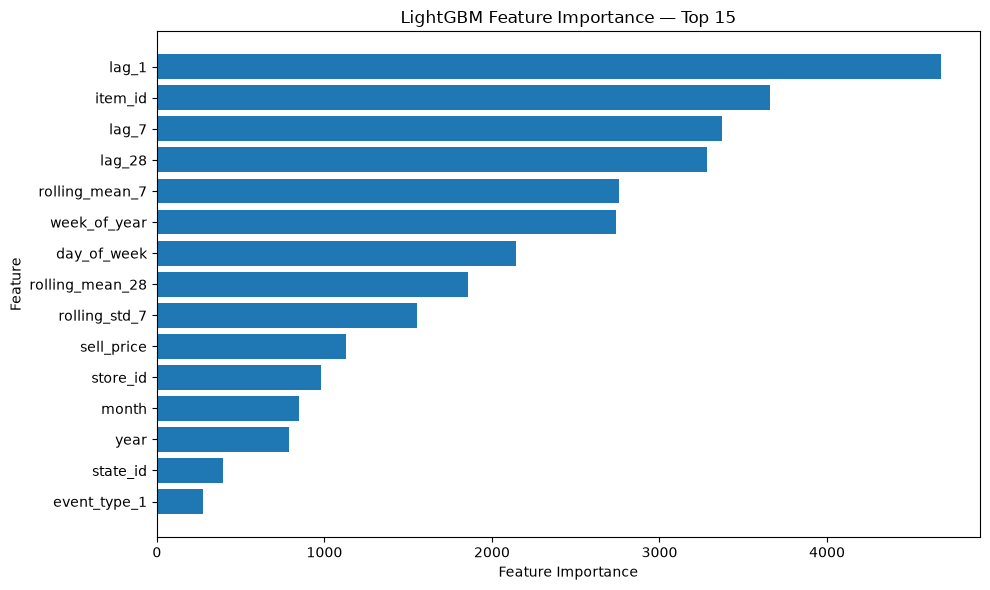

In [128]:
import matplotlib.pyplot as plt

top_importance = (
    importance
    .head(15)
    .sort_values("importance")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_importance["feature"],
    top_importance["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("LightGBM Feature Importance — Top 15")

plt.tight_layout()
plt.show()

In [129]:
validation_results = validation[
    ["date", "sales"]
].copy()

validation_results["prediction"] = validation_predictions

daily_results = (
    validation_results
    .groupby("date")
    .agg(
        actual_sales=("sales", "sum"),
        predicted_sales=("prediction", "sum")
    )
    .reset_index()
)

print(daily_results.head())
print("\nNumber of days:", len(daily_results))

        date  actual_sales  predicted_sales
0 2016-03-28         10345     11103.845622
1 2016-03-29         10093     10316.381520
2 2016-03-30          9397     10309.470178
3 2016-03-31         10023     10334.100034
4 2016-04-01         13173     12210.499387

Number of days: 28


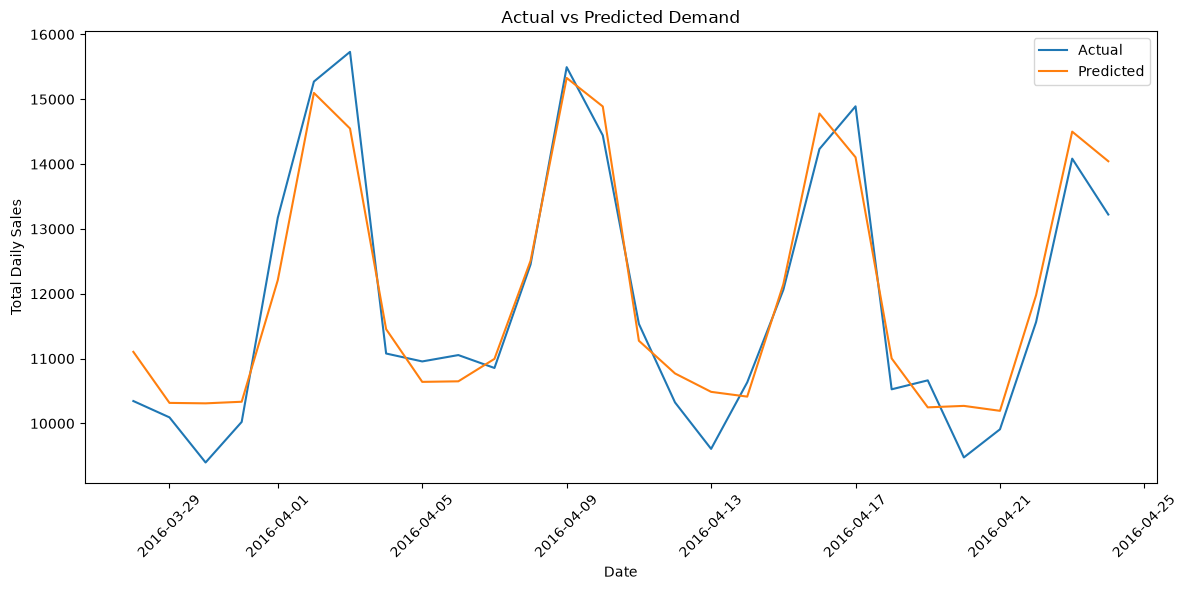

In [130]:
plt.figure(figsize=(12, 6))

plt.plot(
    daily_results["date"],
    daily_results["actual_sales"],
    label="Actual"
)

plt.plot(
    daily_results["date"],
    daily_results["predicted_sales"],
    label="Predicted"
)

plt.xlabel("Date")
plt.ylabel("Total Daily Sales")
plt.title("Actual vs Predicted Demand")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [131]:
daily_results["absolute_error"] = (
    daily_results["actual_sales"]
    - daily_results["predicted_sales"]
).abs()

daily_results["percentage_error"] = (
    daily_results["absolute_error"]
    / daily_results["actual_sales"]
) * 100

print(
    daily_results[
        [
            "date",
            "actual_sales",
            "predicted_sales",
            "absolute_error",
            "percentage_error"
        ]
    ]
)

         date  actual_sales  predicted_sales  absolute_error  percentage_error
0  2016-03-28         10345     11103.845622      758.845622          7.335385
1  2016-03-29         10093     10316.381520      223.381520          2.213232
2  2016-03-30          9397     10309.470178      912.470178          9.710229
3  2016-03-31         10023     10334.100034      311.100034          3.103861
4  2016-04-01         13173     12210.499387      962.500613          7.306617
5  2016-04-02         15273     15097.828718      175.171282          1.146934
6  2016-04-03         15731     14548.630484     1182.369516          7.516175
7  2016-04-04         11078     11453.388184      375.388184          3.388592
8  2016-04-05         10956     10640.617813      315.382187          2.878625
9  2016-04-06         11054     10649.256779      404.743221          3.661509
10 2016-04-07         10855     10995.358276      140.358276          1.293029
11 2016-04-08         12452     12508.887777       5

In [132]:
worst_days = (
    daily_results
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(10)
)

print(worst_days)

         date  actual_sales  predicted_sales  absolute_error  percentage_error
6  2016-04-03         15731     14548.630484     1182.369516          7.516175
4  2016-04-01         13173     12210.499387      962.500613          7.306617
2  2016-03-30          9397     10309.470178      912.470178          9.710229
16 2016-04-13          9607     10486.750455      879.750455          9.157390
27 2016-04-24         13222     14043.824516      821.824516          6.215584
23 2016-04-20          9475     10270.254012      795.254012          8.393182
20 2016-04-17         14891     14105.053017      785.946983          5.278000
0  2016-03-28         10345     11103.845622      758.845622          7.335385
19 2016-04-16         14232     14779.840648      547.840648          3.849358
21 2016-04-18         10526     11002.284829      476.284829          4.524842


In [133]:
best_days = (
    daily_results
    .sort_values(
        "absolute_error",
        ascending=True
    )
    .head(10)
)

print(best_days)

         date  actual_sales  predicted_sales  absolute_error  percentage_error
11 2016-04-08         12452     12508.887777       56.887777          0.456857
18 2016-04-15         12060     12146.634693       86.634693          0.718364
10 2016-04-07         10855     10995.358276      140.358276          1.293029
12 2016-04-09         15495     15328.786144      166.213856          1.072693
5  2016-04-02         15273     15097.828718      175.171282          1.146934
17 2016-04-14         10633     10413.247985      219.752015          2.066698
1  2016-03-29         10093     10316.381520      223.381520          2.213232
14 2016-04-11         11535     11274.915365      260.084635          2.254743
24 2016-04-21          9909     10194.093748      285.093748          2.877119
3  2016-03-31         10023     10334.100034      311.100034          3.103861


In [134]:
wmape_improvement = (
    (wmape - model_wmape)
    / wmape
) * 100

mae_improvement = (
    (baseline_mae - model_mae)
    / baseline_mae
) * 100

rmse_improvement = (
    (baseline_rmse - model_rmse)
    / baseline_rmse
) * 100

print(
    f"MAE improvement: {mae_improvement:.2f}%"
)

print(
    f"RMSE improvement: {rmse_improvement:.2f}%"
)

print(
    f"WMAPE improvement: {wmape_improvement:.2f}%"
)

MAE improvement: 25.57%
RMSE improvement: 29.38%
WMAPE improvement: 25.57%


In [135]:
comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "LightGBM"
    ],
    "MAE": [
        baseline_mae,
        model_mae
    ],
    "RMSE": [
        baseline_rmse,
        model_rmse
    ],
    "WMAPE (%)": [
        wmape * 100,
        model_wmape * 100
    ]
})

comparison

,Model,MAE,RMSE,WMAPE (%)
0,Seasonal Naive,4.708262,8.184868,59.366725
1,LightGBM,3.504556,5.780460,44.189135


# Modeling Findings

## Forecasting Performance

A seasonal-naive baseline using demand from the same day of the
previous week achieved a WMAPE of 59.37%.

The LightGBM model achieved a WMAPE of 44.19%, representing a
25.57% reduction in WMAPE relative to the seasonal-naive baseline.

| Model | MAE | RMSE | WMAPE |
|---|---:|---:|---:|
| Seasonal Naive | 4.71 | 8.18 | 59.37% |
| LightGBM | 3.50 | 5.78 | 44.19% |

## Feature Importance

The most important features were:

1. `lag_1`
2. `item_id`
3. `lag_7`
4. `lag_28`
5. `rolling_mean_7`
6. `week_of_year`
7. `day_of_week`
8. `rolling_mean_28`
9. `rolling_std_7`
10. `sell_price`

The model relied most heavily on recent demand history, product-level
differences, weekly seasonality, longer-term seasonal patterns,
demand volatility, and price.

These results are consistent with the patterns identified during EDA.

## Forecast Behavior

At the aggregate daily level, the model generally tracked the
overall demand pattern across the 28-day validation period.

The strongest forecasts had errors below 1%, while the largest
aggregate daily errors were below 10%.

## Business Interpretation

The results demonstrate that retail demand can be forecast more
effectively by combining historical demand patterns with calendar,
product, store, and pricing information rather than relying solely
on the previous week's demand.

The resulting forecasts provide a foundation for inventory planning
decisions such as safety stock, reorder points, and stockout-risk
prioritization.

## Conclusion

LightGBM substantially outperformed the seasonal-naive baseline,
reducing WMAPE by 25.57% and RMSE by 29.38%.

The model therefore provides a stronger foundation for the next stage
of the project: translating demand forecasts into inventory analytics
and business recommendations.